# Decision tree: do its assumptions hold, and if so, how accurate is it?

**Goal:** give every booking a chance (0 to 1) of cancelling, then judge those chances the way the client does (`contract.py`).

A decision tree asks a chain of yes/no questions about the clues ("lead time over 90 days?") and ends in a leaf that holds the share of similar bookings that cancelled. It makes no assumption about the shape of the data, so its checklist is shorter and about *whether there is enough data and signal for the tree we plan to grow*.

**What this notebook does, in order**

1. **Set up** and load the bookings, split by time into *train* (the model learns), *choose* (we pick settings and the buffer) and *proof* (the final exam).
2. **Check the assumptions** of decision tree on the train period.
3. **Gate.** If every *must-pass* assumption holds, we train. If one fails, the notebook stops and says which.
4. **Train** on train only.
5. **Accuracy**: ordinary classification scores on the choose period.
6. **Accuracy by the contract**: turn the chances into *k* (extra rooms to sell) and score euros, empty rooms, walked guests and walks per 1,000, next to the client's flat rule.
7. **Proof** (the final exam, off by default).

This notebook replaces the decision tree part of `src/all_models.py`. The *k* step in section 6 is the same rule as in `06_k_calculator.ipynb`.

## 1. Set up

In [1]:
import importlib.util
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, log_loss,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text

pd.set_option("display.max_colwidth", 130)
pd.set_option("display.width", 200)

# --- where is everything? (works whether Jupyter starts in notebooks/ or in the project root) ---
HERE = Path.cwd().resolve()
ROOT = next(p for p in [HERE, *HERE.parents] if (p / "src" / "features.py").exists())
NOTES, SRC = ROOT / "notes", ROOT / "src"
for folder in (NOTES, SRC):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

import data               # the starter's data.py: reads hotels.csv (and downloads it if it is missing)
import features           # src/features.py: our cleaning + the Bin 1 clue columns (known on the day of booking)


def load_contract():
    """Load the client's scoring file. We use it exactly as it is and never edit it."""
    for folder in (NOTES, SRC, SRC / "__pycache__"):
        path = folder / "contract.py"
        if path.exists():
            spec = importlib.util.spec_from_file_location("contract", path)
            module = importlib.util.module_from_spec(spec)
            spec.loader.exec_module(module)
            print("scoring file loaded from:", path.relative_to(ROOT))
            return module
    raise FileNotFoundError("contract.py was not found in notes/ or src/")


contract = load_contract()

# --- chart look: one blue line, one orange highlight, quiet grid, dark text ---
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlelocation": "left", "axes.titlesize": 11,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 10,
})

scoring file loaded from: src/contract.py


Three switches control the run:

| Switch | Default | Meaning |
|---|---|---|
| `TUNE` | `False` | `True` runs the two-stage search on **train only** (slower), shows every trial, and saves the best setting to `models/hyperparams.json`. `False` shows the results saved by the last run. |
| `RUN_PROOF` | `False` | The proof period is the final exam. Keep it `False` while experimenting. |
| `FORCE_TRAIN` | `False` | `True` trains even if a *must-pass* assumption fails. Not recommended. |

In [2]:
TUNE = True          # True  = run the tuning searches on TRAIN and save the best (slower). False = show the results saved by the last run
RUN_PROOF = False     # the proof period is the FINAL exam: leave this False until everything is decided
FORCE_TRAIN = False   # True  = train even if a MUST-PASS assumption fails (not recommended)


# Starting settings of the tree (used by the assumption checks and by training)
MAX_DEPTH = 6          # at most 6 questions in a row
MIN_LEAF = 100         # every leaf must hold at least 100 bookings (big leaves = smoother, better calibrated chances)

## 2. Load the bookings and split them by time

In [3]:
raw = data.read_raw()                                     # every booking, exactly as exported
bookings = features.clean_bookings(raw)            # the documented cleaning choices
train, choose, proof = contract.split_periods(bookings)   # split by arrival date, as the contract says
train, choose, proof = [features.add_features(part) for part in (train, choose, proof)]

FEATURES = features.bin1_features                  # the clues known on the day of booking
NUMERIC = features.bin1_numeric_cols
CATEGORICAL = features.bin1_categorical_cols

print(f"bookings: train {len(train):,} | choose {len(choose):,} | proof {len(proof):,}")
print("The proof bookings are loaded but never looked at (no scores, no labels) until RUN_PROOF = True.")

bookings: train 49,108 | choose 29,482 | proof 40,619
The proof bookings are loaded but never looked at (no scores, no labels) until RUN_PROOF = True.


## 3. Do the assumptions of a decision tree hold?

We test them on the **train period only**. Each check is either **must pass** (FAIL stops the notebook) or **advisory** (WARN: noted, we still train).

**What a tree does *not* need** (so we do not test it): no scaling, no straight-line relationships, no normal distributions, and correlated clues do not break it. That is why the list below is short.

| # | Assumption | Why it matters here | How it is tested | Type |
|---|---|---|---|---|
| A1 | The outcome is yes/no | We grow a classification tree | `is_canceled` holds only 0 and 1 | must pass |
| A2 | No leakage | A clue only known after the stay gives the answer away | no clue comes from Bin 2 or Bin 3 | must pass |
| A3 | No gaps | The pipeline has no imputer | count empty cells | must pass |
| A4 | Scoring columns present | `contract.nightly_table` needs them | check the names | must pass |
| A5 | Periods follow each other in time | Train before choose before proof | compare dates | must pass |
| A6 | Neither outcome is rare | With a rare outcome, accuracy is misleading | rarer outcome >= 10% | advisory |
| A7 | The past looks like the future | A tree cannot extrapolate: it only repeats what it saw in train | cancel-rate gap and unseen values | must pass |
| T1 | Enough rows to fill the leaves | A tree of depth 6 has up to 2^6 leaves; each should still hold `MIN_LEAF` bookings | rows / 2^depth >= `MIN_LEAF` | must pass |
| T2 | Enough of the rarer outcome | A leaf's chance is a share; it needs cancellations *and* stays inside it | rarer outcome >= 10 x `MIN_LEAF` | must pass |
| T3 | The clues carry signal a tree can find | If a pilot tree cannot beat guessing on unseen data, there is nothing to learn | pilot AUC >= 0.55 on the newest 20% of train | must pass |
| T4 | No constant clue | A clue with one value can never split anything | count distinct values | advisory |
| | Independent bookings | The chances of bookings on a night are added as if independent | **tested after fitting**, in section 6 | diagnostic |

In [4]:
CHECKS = []    # one row per assumption


def check(name, passed, evidence, must_pass=True):
    """Record one assumption.
       must_pass=True  -> if it fails the status is FAIL and training is stopped.
       must_pass=False -> if it fails the status is WARN: we note it and still train."""
    status = "PASS" if passed else ("FAIL" if must_pass else "WARN")
    CHECKS.append({"assumption": name, "status": status,
                   "type": "must pass" if must_pass else "advisory", "evidence": evidence})

def make_preparer(scale_numbers):
    """Turn the clue columns into numbers. Everything it learns, it learns from the rows it is fitted on."""
    text_step = OneHotEncoder(handle_unknown="ignore", min_frequency=20)   # rare values are grouped together
    number_step = StandardScaler() if scale_numbers else "passthrough"
    return ColumnTransformer([
        ("text", text_step, CATEGORICAL),
        ("numbers", number_step, NUMERIC),
    ])

### A. Checks every model needs (data and contract)

In [5]:
y_train = train["is_canceled"]

# A1. the outcome is a yes/no column with both answers present
check("A1  The outcome is yes/no, with no gaps",
      set(y_train.unique()) == {0, 1} and y_train.notna().all(),
      f"values {sorted(int(v) for v in y_train.unique())}; {y_train.mean():.1%} of train bookings cancelled")

# A2. no clue that is only known AFTER the booking (Bin 2 / Bin 3 columns, or the answer itself)
not_known_at_booking = set(features.bin2_features) | set(features.bin3_features) | {"is_canceled"}
leaky = sorted(set(FEATURES) & not_known_at_booking)
check("A2  No clue that is only known after booking (no leakage)", not leaky,
      f"{len(FEATURES)} clues used; leaky ones: {leaky or 'none'}")

# A3. no empty cells (the pipelines below have no imputer)
gaps = int(train[FEATURES].isna().sum().sum() + choose[FEATURES].isna().sum().sum())
check("A3  No missing values in the clues", gaps == 0, f"{gaps} empty cells in train + choose")

# A4. the columns the scoring file needs
missing_columns = [c for c in contract.REQUIRED if c not in train.columns]
check("A4  The scoring file's columns are present", not missing_columns,
      f"needs {contract.REQUIRED}; missing: {missing_columns or 'none'}")

# A5. the periods follow each other in time (dates only; no proof labels are used)
split_ok = (len(train) > 0 and len(choose) > 0
            and train["arrival_date"].max() < pd.Timestamp(contract.TRAIN_END) <= choose["arrival_date"].min()
            and choose["arrival_date"].max() < pd.Timestamp(contract.PROOF_START))
check("A5  Train, choose and proof follow each other in time", split_ok,
      f"train ends {train['arrival_date'].max().date()}; choose {choose['arrival_date'].min().date()} "
      f"to {choose['arrival_date'].max().date()}")

# A6. neither outcome is rare (advisory)
rarer = min(y_train.mean(), 1 - y_train.mean())
check("A6  Both outcomes are common enough (rarer one >= 10%)", rarer >= 0.10,
      f"the rarer outcome is {rarer:.1%} of train", must_pass=False)

# A7. the past looks like the future: we learn on train and use the model on later nights
rate_gap = abs(choose["is_canceled"].mean() - y_train.mean())
unseen = max((~choose[c].isin(train[c].unique())).mean() for c in CATEGORICAL)
check("A7  The choose period looks like train (cancel-rate gap <= 10 points, unseen values <= 10%)",
      rate_gap <= 0.10 and unseen <= 0.10,
      f"cancel rate {y_train.mean():.1%} -> {choose['is_canceled'].mean():.1%}; "
      f"most unseen values in any one column: {unseen:.1%}")

### B. Checks specific to a decision tree

In [6]:
# T1. enough rows to fill the leaves of the tree we plan to grow
rows_per_leaf = len(train) / 2 ** MAX_DEPTH
check(f"T1  Enough rows to fill the leaves (rows / 2^depth >= {MIN_LEAF})", rows_per_leaf >= MIN_LEAF,
      f"{len(train):,} rows / 2^{MAX_DEPTH} leaves = {rows_per_leaf:,.0f} rows per leaf")

# T2. enough of the rarer outcome for leaves to hold both answers
events = int(min(y_train.sum(), (1 - y_train).sum()))
check(f"T2  Enough of the rarer outcome (>= 10 x MIN_LEAF = {10 * MIN_LEAF:,})", events >= 10 * MIN_LEAF,
      f"{events:,} cases of the rarer outcome")

# T3. pilot: a tree trained on the OLDER 80% of train must find signal in the NEWEST 20%
ordered = train.sort_values("arrival_date")
cut = int(len(ordered) * 0.8)
older, newer = ordered.iloc[:cut], ordered.iloc[cut:]
pilot = Pipeline([("prepare", make_preparer(scale_numbers=False)),
                  ("model", DecisionTreeClassifier(max_depth=MAX_DEPTH, min_samples_leaf=MIN_LEAF, random_state=0))])
pilot.fit(older[FEATURES], older["is_canceled"])
pilot_auc = roc_auc_score(newer["is_canceled"], pilot.predict_proba(newer[FEATURES])[:, 1])
check("T3  The clues carry signal a tree can find (pilot AUC >= 0.55 on unseen data)", pilot_auc >= 0.55,
      f"pilot tree AUC on the newest 20% of train = {pilot_auc:.3f} (0.5 = guessing)")

# T4. no constant clue (advisory)
constant = [c for c in FEATURES if train[c].nunique() <= 1]
check("T4  No clue is constant", not constant, f"constant clues: {constant or 'none'}", must_pass=False)

### Verdict

All checks are collected into one table. **FAIL** = a must-pass assumption is broken. **WARN** = an advisory one is, and we carry on.

In [7]:
report = pd.DataFrame(CHECKS).set_index("assumption")
display(report)

failed = report.index[report["status"] == "FAIL"].tolist()
warned = report.index[report["status"] == "WARN"].tolist()
ASSUMPTIONS_OK = not failed
TRAIN_MODEL = ASSUMPTIONS_OK or FORCE_TRAIN

print(f"{(report['status'] == 'PASS').sum()} passed | {len(warned)} warning(s) | {len(failed)} failed")
for name in warned:
    print("   WARN:", name.strip())

if not ASSUMPTIONS_OK:
    verdict = "FAILED (trained anyway: FORCE_TRAIN)"
elif warned:
    verdict = f"PASS with {len(warned)} warning(s)"
else:
    verdict = "PASS"

if not TRAIN_MODEL:
    raise RuntimeError("Must-pass assumption(s) failed, so decision tree is NOT trained: "
                       + "; ".join(n.strip() for n in failed)
                       + ". Fix the cause, or set FORCE_TRAIN = True to train anyway.")
print("\nVerdict:", "the must-pass assumptions hold -> we train the decision tree." if ASSUMPTIONS_OK
      else "FORCE_TRAIN is on -> training even though a must-pass assumption failed.")

,status,type,evidence
assumption,,,
"A1 The outcome is yes/no, with no gaps",PASS,must pass,"values [0, 1]; 35.8% of train bookings cancelled"
A2 No clue that is only known after booking (no leakage),PASS,must pass,14 clues used; leaky ones: none
A3 No missing values in the clues,PASS,must pass,0 empty cells in train + choose
A4 The scoring file's columns are present,PASS,must pass,"needs ['hotel', 'arrival_date', 'is_canceled', 'adr', 'nights']; missing: none"
"A5 Train, choose and proof follow each other in time",PASS,must pass,train ends 2016-06-30; choose 2016-07-01 to 2016-12-31
A6 Both outcomes are common enough (rarer one >= 10%),PASS,advisory,the rarer outcome is 35.8% of train
"A7 The choose period looks like train (cancel-rate gap <= 10 points, unseen values <= 10%)",PASS,must pass,cancel rate 35.8% -> 36.9%; most unseen values in any one column: 1.7%
T1 Enough rows to fill the leaves (rows / 2^depth >= 100),PASS,must pass,"49,108 rows / 2^6 leaves = 767 rows per leaf"
"T2 Enough of the rarer outcome (>= 10 x MIN_LEAF = 1,000)",PASS,must pass,"17,581 cases of the rarer outcome"


11 passed | 0 warning(s) | 0 failed

Verdict: the must-pass assumptions hold -> we train the decision tree.


## 4. Tune and train the decision tree

Only reached if the gate above passed. This section shows **how the settings were chosen**: what we tune and why, a wide search, a finer search, a plot, the best setting, and a check that tuning really helps. Every search uses **train only**, in folds that go forward in time, so nothing from the choose or proof periods can influence the choice. Text clues are one-hot encoded (rare values grouped, fitted on train only); numeric clues are used as they are, because a tree does not need scaling.

`TUNE = True` runs the searches (slower) and saves the result. `TUNE = False` shows the results saved by the last run.

In [8]:
import datetime
import json

import all_models                                   # src/all_models.py: the same trainers backtest.py uses
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_validate

# ---- how every search in this section is run ----
SEED = 0                                  # fixed seed: the random search (step 2) tries the same candidates every run
N_SPLITS = 3
CV = TimeSeriesSplit(n_splits=N_SPLITS)   # each fold is tested on bookings that come AFTER the ones it learned from
SCORING = {"log_loss": "neg_log_loss", "auc": "roc_auc"}   # log loss decides; AUC is shown for reference
PREFER_SIMPLER = False    # True = among candidates tied with the best, take the simplest (step 5). False = take the lowest log loss

ordered = train.sort_values("arrival_date")               # time order, as TimeSeriesSplit needs
X_tune, y_tune = ordered[FEATURES], ordered["is_canceled"]

SETTINGS = ["max_depth", "min_samples_leaf", "criterion"]                    # one column per setting in the trials table
NUMERIC_SETTINGS = ["max_depth", "min_samples_leaf"]             # the ones that have a range (edge check and plot)
INT_SETTINGS = ["max_depth", "min_samples_leaf"]

EVIDENCE = ROOT / "evidence"
TRIALS_FILE = EVIDENCE / "tuning_decision_tree_trials.csv"   # every candidate that was tried
SUMMARY_FILE = EVIDENCE / "tuning_decision_tree.json"        # how the search was run + the choice


def number_or_text(v):
    """A CSV stores 0.3 and 'sqrt' in the same column as text: turn the numbers back into numbers."""
    try:
        return float(v)
    except (TypeError, ValueError):
        return v


def tidy_trials(df):
    """A CSV turns None into an empty cell: put it back, so a saved table behaves like a fresh one."""
    df = df.copy()
    if "max_depth" in df:
        df["max_depth"] = pd.Series([None if pd.isna(v) else int(v) for v in df["max_depth"]], index=df.index, dtype=object)
    if "max_features" in df:
        df["max_features"] = pd.Series([number_or_text(v) for v in df["max_features"]], index=df.index, dtype=object)
    return df


trials = summary = None
if not TUNE:
    if TRIALS_FILE.exists() and SUMMARY_FILE.exists():
        trials = tidy_trials(pd.read_csv(TRIALS_FILE))
        summary = json.loads(SUMMARY_FILE.read_text())
        print("TUNE = False: showing the results saved by the last tuning run.")
    else:
        print("TUNE = False and nothing is saved yet. Set TUNE = True at the top and run the notebook once.")

### Step 1. What are we tuning, and why these values?

A *hyper-parameter* is a setting we choose before training. The model cannot learn it from the data, so we try values and keep the ones that predict best on bookings it has not seen. The decision tree has three that matter here.

In [9]:
TUNED = pd.DataFrame([
    {"setting": "max_depth",
     "what it controls": "how many yes/no questions in a row the tree may ask. Small = a coarse tree (underfits); large = a tree that memorises single bookings (overfits)",
     "range tried": "2, 3, 4, 5, 6, 8, 10, 12, 16, 20 (step 2), then the values within 2 of the best (step 3)",
     "why this range": "2 questions is clearly too coarse and 20 is deep enough to isolate a handful of bookings, so the best depth cannot be hiding outside it"},
    {"setting": "min_samples_leaf",
     "what it controls": "the smallest number of bookings a leaf may hold. Small = leaves that follow noise (overfits); large = every chance is an average over many bookings (smoother, but may underfit)",
     "range tried": "10, 20, 50, 100, 200, 400, 800 (step 2), then half to double the best (step 3)",
     "why this range": "from tiny leaves to leaves holding ~1.5% of train. Roughly doubling steps, because leaf size matters in multiples, not in equal steps"},
    {"setting": "criterion",
     "what it controls": "how a split is scored: gini or entropy (both measure how mixed a group is)",
     "range tried": "gini, entropy",
     "why this range": "these are the two choices; they usually give very similar trees, so this setting is expected to matter least"},
]).set_index("setting")
with pd.option_context("display.max_colwidth", None):
    display(TUNED)
print("Not tuned: random_state = 0 (the same tree every run), class weights (not set: the chances must stay honest, "
      "so the classes are not re-balanced), the encoding (fixed in features.py).")

,what it controls,range tried,why this range
setting,,,
max_depth,how many yes/no questions in a row the tree may ask. Small = a coarse tree (underfits); large = a tree that memorises single bookings (overfits),"2, 3, 4, 5, 6, 8, 10, 12, 16, 20 (step 2), then the values within 2 of the best (step 3)","2 questions is clearly too coarse and 20 is deep enough to isolate a handful of bookings, so the best depth cannot be hiding outside it"
min_samples_leaf,"the smallest number of bookings a leaf may hold. Small = leaves that follow noise (overfits); large = every chance is an average over many bookings (smoother, but may underfit)","10, 20, 50, 100, 200, 400, 800 (step 2), then half to double the best (step 3)","from tiny leaves to leaves holding ~1.5% of train. Roughly doubling steps, because leaf size matters in multiples, not in equal steps"
criterion,how a split is scored: gini or entropy (both measure how mixed a group is),"gini, entropy","these are the two choices; they usually give very similar trees, so this setting is expected to matter least"


Not tuned: random_state = 0 (the same tree every run), class weights (not set: the chances must stay honest, so the classes are not re-balanced), the encoding (fixed in features.py).


### Step 2. Wide search: try many combinations

The three settings together make 10 x 7 x 2 = 140 combinations. Training all of them on three folds is slow, so a **random search** tries 30 of them (the same 30 every run, because the seed is fixed). Every candidate is scored on the same three forward-in-time folds. The table lists every candidate, best first. **`log loss`** decides (lower is better), because the safety buffer is built from the *sum* of the chances, so the chances must be honest. `log loss std` is how much the score moved between folds, and `AUC` is shown for reference. The **edge check** below the table says whether the best value sits at the end of a range, which would mean the range is too narrow.

In [10]:
def base_model():
    """The model with the defaults from all_models.py. A search changes only the settings it names."""
    return Pipeline([
        ("prepare", make_preparer(scale_numbers=False)),
        ("model", DecisionTreeClassifier(max_depth=6, min_samples_leaf=100, random_state=0)),   # = the defaults in all_models.py
    ])


def run_search(search):
    """Fit a search on the time-ordered folds. Returns one row per candidate."""
    search.fit(X_tune, y_tune)
    r = pd.DataFrame(search.cv_results_)
    out = pd.DataFrame(index=r.index)
    for s in SETTINGS:
        values = [None if v is None or pd.isna(v) else (int(v) if s in INT_SETTINGS else v) for v in r[f"param_model__{s}"]]
        out[s] = pd.Series(values, index=r.index, dtype=object)       # object, so a None stays a None
    out["log loss"] = -r["mean_test_log_loss"]
    out["log loss std"] = r["std_test_log_loss"]
    out["AUC"] = r["mean_test_auc"]
    out["fit seconds"] = r["mean_fit_time"]
    for k in range(N_SPLITS):                               # the score of every single fold, kept as evidence
        out[f"fold {k + 1}"] = -r[f"split{k}_test_log_loss"]
    return out


# how to put the values of a setting in order, from the lowest to the highest (None = no limit = the highest)
ORDER = {
    "max_depth": lambda v: float("inf") if v is None else v,
    "min_samples_leaf": lambda v: v,
    "n_estimators": lambda v: v,
    "max_features": lambda v: -1 if v == "sqrt" else v,
}


def edge_check(best_row, space):
    """Is the best value at the lowest or highest end of what was searched? Then the range may be too narrow."""
    at_edge = []
    for s in NUMERIC_SETTINGS:
        values = sorted(space[s], key=ORDER[s])
        v = best_row[s]
        if len(values) > 1 and v == values[0]:
            at_edge.append(f"{s} = {v} (the lowest value tried)")
        elif len(values) > 1 and v == values[-1]:
            if v is None:
                print(f"   note: {s} = None means no limit, so it cannot be widened any further.")
            else:
                at_edge.append(f"{s} = {v} (the highest value tried)")
    return at_edge


STAGE1_SPACE = {
    "max_depth": [2, 3, 4, 5, 6, 8, 10, 12, 16, 20],
    "min_samples_leaf": [10, 20, 50, 100, 200, 400, 800],
    "criterion": ["gini", "entropy"],
}
N_ITER = 30

if TUNE:
    stage1 = run_search(RandomizedSearchCV(
        base_model(), {f"model__{k}": v for k, v in STAGE1_SPACE.items()}, n_iter=N_ITER,
        scoring=SCORING, cv=CV, refit=False, random_state=SEED, n_jobs=-1))
    stage1.insert(0, "stage", 1)
    trials = stage1

if trials is not None:
    shown = trials[trials["stage"] == 1].sort_values("log loss").reset_index(drop=True)
    display(shown.round(4))
    print(f"{len(shown)} of the {10 * 7 * 2} possible combinations were tried.")
    best_text = ", ".join(f"{s} = {shown.loc[0, s]}" for s in SETTINGS)
    print(f"Best of the wide search: {best_text}")
    stage1_space = STAGE1_SPACE if TUNE else summary["stage 1 (wide) space"]
    edges = edge_check(shown.loc[0], stage1_space)
    if edges:
        print("-> the best value is at the edge of the range for: " + "; ".join(edges) + ". Widen that range and run again.")
    else:
        print("-> the best values are inside the ranges, so the wide search was wide enough.")

,stage,max_depth,min_samples_leaf,criterion,log loss,log loss std,AUC,fit seconds,fold 1,fold 2,fold 3
0,1,3,10,gini,0.4440,0.0666,0.7854,0.1748,0.3509,0.5029,0.4782
1,1,3,20,gini,0.4517,0.0554,0.7854,0.0865,0.3745,0.5024,0.4782
2,1,8,400,entropy,0.4541,0.0892,0.8331,0.1228,0.3433,0.5617,0.4573
3,1,4,200,gini,0.4553,0.1049,0.8116,0.0864,0.3256,0.5825,0.4578
4,1,5,100,gini,0.4555,0.1022,0.8163,0.1017,0.3344,0.5844,0.4476
5,1,16,400,entropy,0.4560,0.0899,0.8327,0.1009,0.3433,0.5632,0.4616
6,1,2,50,gini,0.4562,0.0652,0.7499,0.0870,0.3640,0.5027,0.5020
7,1,6,400,gini,0.4583,0.0883,0.8309,0.1005,0.3494,0.5657,0.4599
8,1,5,400,gini,0.4602,0.0997,0.8255,0.0934,0.3380,0.5822,0.4605
9,1,4,50,gini,0.4637,0.0986,0.8117,0.0971,0.3437,0.5852,0.4622


30 of the 140 possible combinations were tried.
Best of the wide search: max_depth = 3, min_samples_leaf = 10, criterion = gini
-> the best value is at the edge of the range for: min_samples_leaf = 10 (the lowest value tried). Widen that range and run again.


### Step 3. Finer search around the best region

Now zoom in with a **grid search**: for every setting, the values next to the stage 1 winner (depth within 2, leaf size from half to double, both criteria). Every combination in that small grid is tried.

In [11]:
def make_stage2_space(best):
    """Values close to the stage 1 winner: depth within 2, leaf size from half to double, both criteria."""
    depth, leaf = int(best["max_depth"]), int(best["min_samples_leaf"])
    return {
        "max_depth": sorted({max(2, depth + k) for k in (-2, -1, 0, 1, 2)}),
        "min_samples_leaf": sorted({max(1, round(leaf * f)) for f in (0.5, 0.7, 1, 1.4, 2)}),
        "criterion": ["gini", "entropy"],
    }

if TUNE:
    best_of_stage1 = trials[trials["stage"] == 1].sort_values("log loss").iloc[0]
    STAGE2_SPACE = make_stage2_space(best_of_stage1)
    stage2 = run_search(GridSearchCV(
        base_model(), {f"model__{k}": v for k, v in STAGE2_SPACE.items()},
        scoring=SCORING, cv=CV, refit=False, n_jobs=-1))
    stage2.insert(0, "stage", 2)
    trials = pd.concat([trials, stage2], ignore_index=True)
elif summary is not None:
    STAGE2_SPACE = summary["stage 2 (fine) space"]

if trials is not None:
    shown = trials[trials["stage"] == 2].sort_values("log loss").reset_index(drop=True)
    display(shown.round(4))
    print(f"{len(shown)} combinations tried in the fine search.")
    best_text = ", ".join(f"{s} = {shown.loc[0, s]}" for s in SETTINGS)
    print(f"Best of the fine search: {best_text}")
    edges = edge_check(shown.loc[0], STAGE2_SPACE)
    if edges:
        print("-> the best value is at the edge of the zoomed range for: " + "; ".join(edges)
              + ". The score is still moving, so widen it and run again.")
    else:
        print("-> the best values are inside the zoomed ranges.")

,stage,max_depth,min_samples_leaf,criterion,log loss,log loss std,AUC,fit seconds,fold 1,fold 2,fold 3
0,2,3,10,gini,0.4440,0.0666,0.7854,0.0996,0.3509,0.5029,0.4782
1,2,3,5,gini,0.4444,0.0646,0.7857,0.0872,0.3536,0.4983,0.4814
2,2,3,7,gini,0.4450,0.0671,0.7854,0.0840,0.3509,0.5029,0.4814
3,2,3,14,gini,0.4464,0.0628,0.7854,0.1017,0.3587,0.5024,0.4782
4,2,3,10,entropy,0.4470,0.0597,0.7796,0.1130,0.3637,0.5008,0.4765
5,2,3,7,entropy,0.4481,0.0603,0.7795,0.1076,0.3637,0.5008,0.4797
6,2,3,5,entropy,0.4490,0.0590,0.7795,0.1048,0.3664,0.5008,0.4797
7,2,2,14,gini,0.4496,0.0747,0.7496,0.0828,0.3440,0.5027,0.5020
8,2,2,20,gini,0.4496,0.0747,0.7496,0.0857,0.3440,0.5027,0.5020
9,2,3,20,gini,0.4517,0.0554,0.7854,0.1081,0.3745,0.5024,0.4782


40 combinations tried in the fine search.
Best of the fine search: max_depth = 3, min_samples_leaf = 10, criterion = gini
-> the best values are inside the zoomed ranges.


### Step 4. Where does the model underfit and overfit?

One panel per setting, showing the best score reached at each value. For `max_depth`, the left of the curve underfits (too few questions) and the right overfits (the tree memorises). For `min_samples_leaf` it is the other way round: small leaves overfit, huge leaves underfit. The best value sits where the curve is lowest. The bars show how much the score moved between the three folds, so two values whose bars overlap are not really different.

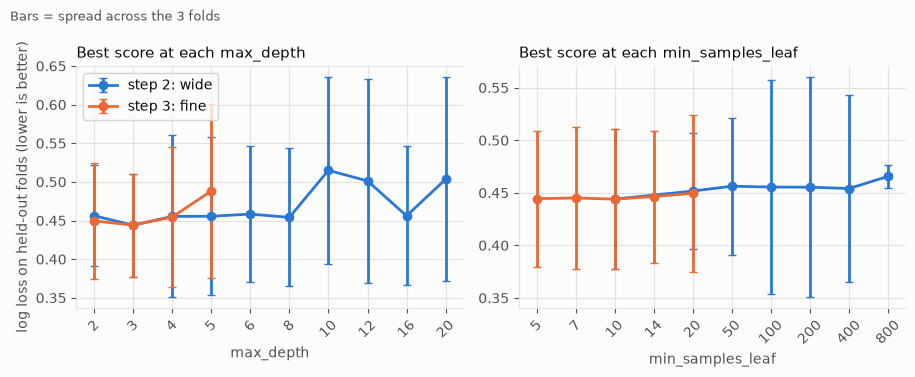

In [12]:
if trials is not None:
    n_panels = len(NUMERIC_SETTINGS)
    fig, axes = plt.subplots(1, n_panels, figsize=(4.6 * n_panels, 3.8), squeeze=False)
    for ax, s in zip(axes[0], NUMERIC_SETTINGS):
        values = sorted(trials[s].unique(), key=ORDER[s])
        position = {v: i for i, v in enumerate(values)}
        for stage, colour, label in ((1, BLUE, "step 2: wide"), (2, ORANGE, "step 3: fine")):
            part = trials[trials["stage"] == stage]
            points = []
            for v in values:                                  # the best score reached at each value of this setting
                rows = part[[x == v for x in part[s]]]
                if len(rows):
                    row = rows.loc[rows["log loss"].idxmin()]
                    points.append((position[v], row["log loss"], row["log loss std"]))
            if points:
                x, y, e = zip(*points)
                ax.errorbar(x, y, yerr=e, marker="o", color=colour, label=label, capsize=3)
        ax.set_xticks(range(len(values)))
        ax.set_xticklabels(["None" if v is None else str(v) for v in values], rotation=45 if len(values) > 8 else 0)
        ax.set_xlabel(s)
        ax.set_title(f"Best score at each {s}")
    axes[0][0].set_ylabel("log loss on held-out folds (lower is better)")
    axes[0][0].legend()
    fig.suptitle("Bars = spread across the 3 folds", x=0.01, ha="left", fontsize=9, color=MUTED)
    fig.tight_layout()
    plt.show()

### Step 5. The best setting

**Rule:** take the lowest log loss. Another candidate counts as *tied* with it if its average gap to the best, measured **fold by fold**, is smaller than one standard error of that gap. (Comparing fold by fold removes the noise all candidates share, such as one fold simply being a harder period.) Among the tied candidates we choose the simplest tree: the smallest `max_depth`, and among those the largest `min_samples_leaf`. A simpler model generalises better and its chances tend to be better calibrated. Set `PREFER_SIMPLER = False` at the top of this section to take the lowest log loss instead. With only 3 folds the standard error is large, so many candidates count as tied: check the chosen row against the plot in step 4.

In [13]:
if trials is not None:
    fold_cols = [f"fold {k + 1}" for k in range(N_SPLITS)]
    pool = trials.drop_duplicates(SETTINGS).copy()          # a combination tried in both searches counts once
    best = pool.sort_values("log loss").iloc[0]
    gap = pool[fold_cols].sub(best[fold_cols], axis=1)      # this candidate minus the best, fold by fold
    pool["gap to best"] = gap.mean(axis=1)
    pool["one std error"] = gap.std(axis=1, ddof=1) / np.sqrt(N_SPLITS)
    tied = pool[pool["gap to best"] <= pool["one std error"]].copy()
    tied = tied.sort_values(["max_depth", "min_samples_leaf"], ascending=[True, False])   # simplest first: shallowest, then biggest leaves
    chosen = tied.iloc[0] if PREFER_SIMPLER else best       # tied.iloc[0] = the simplest of the tied candidates
    chosen_params = {f"model__{s}": chosen[s] for s in SETTINGS}   # exactly what all_models.set_params receives


    def describe(row):
        return ", ".join(f"{s} = {row[s]}" for s in SETTINGS)


    print(f"BEST SETTING:  {describe(chosen)}")
    print(f"  lowest log loss overall: {describe(best)} (log loss {best['log loss']:.4f})")
    if PREFER_SIMPLER:
        print(f"  {len(tied)} candidate(s) are tied with it (gap within one standard error); the simplest of them is chosen")
    else:
        print("  PREFER_SIMPLER = False: the lowest log loss is taken as it is")
    print(f"  chosen: log loss {chosen['log loss']:.4f}, AUC {chosen['AUC']:.4f}")
    display(tied[SETTINGS + ["log loss", "AUC", "gap to best", "one std error"]].round(4).reset_index(drop=True))

    if TUNE:
        summary = {
            "model": "decision tree",
            "tuned_on": (f"train period only ({train['arrival_date'].min().date()} to {train['arrival_date'].max().date()}), "
                         f"{N_SPLITS} forward-in-time folds (TimeSeriesSplit)"),
            "scoring": "mean log loss over the folds (lower is better); AUC recorded for reference",
            "seed": SEED,
            "settings_searched": [f"model__{s}" for s in SETTINGS],
            "stage 1 (wide) search": f"RandomizedSearchCV, n_iter = {N_ITER}",
            "stage 1 (wide) space": STAGE1_SPACE,
            "stage 2 (fine) search": "GridSearchCV over the neighbours of the stage 1 winner",
            "stage 2 (fine) space": STAGE2_SPACE,
            "n_trials": int(len(pool)),
            "prefer_simpler": PREFER_SIMPLER,
            "rule": ("lowest log loss; candidates whose fold-by-fold gap to it is within one standard error count as tied, "
                     "and the simplest of them (smallest max_depth, then largest min_samples_leaf) is chosen" if PREFER_SIMPLER else "lowest log loss"),
            "lowest_log_loss_setting": {f"model__{s}": best[s] for s in SETTINGS},
            "chosen": chosen_params,
            "chosen_log_loss": float(chosen["log loss"]),
        }

BEST SETTING:  max_depth = 3, min_samples_leaf = 10, criterion = gini
  lowest log loss overall: max_depth = 3, min_samples_leaf = 10, criterion = gini (log loss 0.4440)
  PREFER_SIMPLER = False: the lowest log loss is taken as it is
  chosen: log loss 0.4440, AUC 0.7854


,max_depth,min_samples_leaf,criterion,log loss,AUC,gap to best,one std error
0,2,20,gini,0.4496,0.7496,0.0056,0.00933
1,2,14,gini,0.4496,0.7496,0.0056,0.00933
2,3,100,gini,0.4684,0.7869,0.024425,0.032548
3,3,20,gini,0.4517,0.7854,0.007712,0.007953
4,3,14,gini,0.4464,0.7854,0.002429,0.002672
5,3,10,gini,0.4440,0.7854,0.0,0.0
6,3,10,entropy,0.4470,0.7796,0.003034,0.004892
7,3,7,gini,0.4450,0.7854,0.001068,0.001068
8,3,7,entropy,0.4481,0.7795,0.004102,0.004477
9,3,5,gini,0.4444,0.7857,0.000438,0.002487


### Step 6. Does tuning help? Tuned vs default

The default settings (the ones in `all_models.py`) and the chosen settings, scored on the same three folds. If the gain is tiny, tuning did not matter much, and that is also a result worth reporting.

In [14]:
DEFAULT_PARAMS = {"model__max_depth": 6, "model__min_samples_leaf": 100, "model__criterion": "gini"}      # the defaults in all_models.py


def fold_scores(params):
    r = cross_validate(base_model().set_params(**params), X_tune, y_tune, cv=CV, scoring=SCORING, n_jobs=-1)
    return pd.DataFrame({"log loss": -r["test_log_loss"], "AUC": r["test_auc"]}, index=range(1, N_SPLITS + 1))


def params_text(params):
    return ", ".join(f"{k.replace('model__', '')} = {v}" for k, v in params.items())


if trials is not None:
    if TUNE:
        default, tuned = fold_scores(DEFAULT_PARAMS), fold_scores(chosen_params)
        summary["vs_default"] = {
            "default settings": DEFAULT_PARAMS, "chosen settings": chosen_params,
            "default log loss": float(default["log loss"].mean()), "tuned log loss": float(tuned["log loss"].mean()),
            "default AUC": float(default["AUC"].mean()), "tuned AUC": float(tuned["AUC"].mean()),
            "default log loss by fold": [float(x) for x in default["log loss"]],
            "tuned log loss by fold": [float(x) for x in tuned["log loss"]],
        }
    v = summary["vs_default"]
    compare = pd.DataFrame({
        "default": [v["default log loss"], v["default AUC"]],
        "tuned": [v["tuned log loss"], v["tuned AUC"]],
    }, index=["mean log loss (lower is better)", "mean AUC (higher is better)"])
    compare["difference"] = compare["tuned"] - compare["default"]
    print("default:", params_text(v["default settings"]))
    print("tuned:  ", params_text(v["chosen settings"]))
    display(compare.round(4))

    gain = v["default log loss"] - v["tuned log loss"]
    if gain > 0.002:
        print(f"-> tuning helped: the log loss fell by {gain:.4f}.")
    elif gain >= -0.002:
        print(f"-> the difference is tiny ({gain:+.4f} log loss): the default was already close. Report that tuning changed little.")
    else:
        print(f"-> the chosen setting is worse than the default by {-gain:.4f} log loss on these folds. Look at the plot in step 4 before using it.")

default: max_depth = 6, min_samples_leaf = 100, criterion = gini
tuned:   max_depth = 3, min_samples_leaf = 10, criterion = gini


,default,tuned,difference
mean log loss (lower is better),0.4510,0.4440,-0.0070
mean AUC (higher is better),0.8295,0.7854,-0.0441


-> tuning helped: the log loss fell by 0.0070.


### Step 7. Save the choice

With `TUNE = True` this saves three things: the chosen settings in `models/hyperparams.json` (what `backtest.py` trains with), and the full table of trials plus the search summary in `evidence/` (the proof of how the settings were chosen). It also prints a row for `docs/DECISIONS.md`: check the wording, then paste it into the team decisions table.

In [15]:
if TUNE and summary is not None:
    EVIDENCE.mkdir(exist_ok=True)
    trials.to_csv(TRIALS_FILE, index=False)
    SUMMARY_FILE.write_text(json.dumps(summary, indent=2))
    all_models.save_hyperparams("decision tree", summary["chosen"])
    print("saved: models/hyperparams.json  (the settings backtest.py trains with)")
    print("saved:", TRIALS_FILE.relative_to(ROOT), "and", SUMMARY_FILE.relative_to(ROOT))

if summary is not None:
    v = summary["vs_default"]
    print("\nRow for docs/DECISIONS.md (team decisions table). Check the wording before you paste it:\n")
    print(f"| {datetime.date.today()} | notebooks/04_model_decision_tree.ipynb | Decision tree: {params_text(v['chosen settings'])}. "
          f"Chosen from {summary['n_trials']} trials (max_depth 2 to 20, min_samples_leaf 10 to 800, gini or entropy) on train only, {N_SPLITS} forward-in-time folds, scored by log loss. "
          f"Rule: {summary['rule']}. "
          f"Cross-validated log loss {v['tuned log loss']:.4f} against {v['default log loss']:.4f} for the defaults ({params_text(v['default settings'])}). | | | |")

saved: models/hyperparams.json  (the settings backtest.py trains with)
saved: evidence/tuning_decision_tree_trials.csv and evidence/tuning_decision_tree.json

Row for docs/DECISIONS.md (team decisions table). Check the wording before you paste it:

| 2026-11-17 | notebooks/04_model_decision_tree.ipynb | Decision tree: max_depth = 3, min_samples_leaf = 10, criterion = gini. Chosen from 64 trials (max_depth 2 to 20, min_samples_leaf 10 to 800, gini or entropy) on train only, 3 forward-in-time folds, scored by log loss. Rule: lowest log loss. Cross-validated log loss 0.4440 against 0.4510 for the defaults (max_depth = 6, min_samples_leaf = 100, criterion = gini). | | | |


### Train the final model

The model used in the rest of this notebook is trained by `all_models.train_tree`, the same function `backtest.py` calls, with the saved settings. So the notebook and `backtest.py` always train the same model.

In [16]:
model = all_models.train_tree(train)                      # learn from train only, with the saved settings
print("settings used:", all_models.load_hyperparams("decision tree") or "none saved yet, so the defaults")
print("trained on", f"{len(train):,}", "train bookings")
tree = model.named_steps["model"]
print(f"depth {tree.get_depth()}, {tree.get_n_leaves()} leaves")

settings used: {'model__max_depth': 3, 'model__min_samples_leaf': 10, 'model__criterion': 'gini'}
trained on 49,108 train bookings
depth 3, 8 leaves


In [17]:
# The first three questions the tree asks (class 1 = cancelled)
names = list(model.named_steps["prepare"].get_feature_names_out())
print(export_text(tree, feature_names=names, max_depth=3))

|--- text__deposit_type_Non Refund <= 0.50
|   |--- numbers__previous_cancellations <= 0.50
|   |   |--- text__market_segment_Online TA <= 0.50
|   |   |   |--- class: 0
|   |   |--- text__market_segment_Online TA >  0.50
|   |   |   |--- class: 0
|   |--- numbers__previous_cancellations >  0.50
|   |   |--- numbers__previous_bookings_not_canceled <= 0.50
|   |   |   |--- class: 1
|   |   |--- numbers__previous_bookings_not_canceled >  0.50
|   |   |   |--- class: 0
|--- text__deposit_type_Non Refund >  0.50
|   |--- text__agent_298 <= 0.50
|   |   |--- text__company_51 <= 0.50
|   |   |   |--- class: 1
|   |   |--- text__company_51 >  0.50
|   |   |   |--- class: 1
|   |--- text__agent_298 >  0.50
|   |   |--- numbers__lead_time <= 177.00
|   |   |   |--- class: 0
|   |   |--- numbers__lead_time >  177.00
|   |   |   |--- class: 1



## 5. Accuracy on the choose period

The model learned from train only, so the choose period is data it has never seen. First the ordinary scores, then (section 6) the scores that matter to the client.

In [18]:
def predict_chances(model, df):
    """A chance of cancelling (0 to 1) for every booking."""
    return model.predict_proba(df[FEATURES])[:, 1]     # column 0 = chance of staying, column 1 = chance of cancelling


def get_scores(df, chances):
    """Ordinary classification scores, using 0.5 as the cut-off."""
    answers = df["is_canceled"]
    guesses = (chances >= 0.5).astype(int)
    true_stays, false_cancels, missed_cancels, true_cancels = confusion_matrix(answers, guesses).ravel()
    return {
        "accuracy": accuracy_score(answers, guesses),             # share of bookings guessed right
        "always_stays": 1 - answers.mean(),                       # accuracy if we just said "nobody cancels"
        "auc": roc_auc_score(answers, chances),                   # 0.5 = guessing, 1.0 = perfect
        "log_loss": log_loss(answers, chances),                   # punishes confident wrong chances
        "precision": precision_score(answers, guesses, zero_division=0),   # of "will cancel" guesses, how many did
        "recall": recall_score(answers, guesses),                 # of the real cancels, how many we caught
        "f1": f1_score(answers, guesses),                         # one number mixing precision and recall
        "true_stays": true_stays, "false_cancels": false_cancels,
        "missed_cancels": missed_cancels, "true_cancels": true_cancels,
    }


def show_scores(scores, chances, df):
    table = pd.Series({
        "accuracy": scores["accuracy"],
        "accuracy of always guessing 'stays' (the bar to beat)": scores["always_stays"],
        "AUC": scores["auc"], "log loss": scores["log_loss"],
        "precision": scores["precision"], "recall": scores["recall"], "f1": scores["f1"],
    }, name="choose period")
    display(table.round(3).to_frame())
    display(pd.DataFrame([[scores["true_stays"], scores["false_cancels"]],
                          [scores["missed_cancels"], scores["true_cancels"]]],
                         index=["really stayed", "really cancelled"],
                         columns=["guessed: stays", "guessed: cancels"]))
    beat = "BEATS" if scores["accuracy"] > scores["always_stays"] else "does NOT beat"
    print(f"Accuracy {scores['accuracy']:.3f} {beat} the always-'stays' guess ({scores['always_stays']:.3f}).")
    expected, actual = chances.sum(), int(df["is_canceled"].sum())
    print(f"Chances add up to {expected:,.0f} cancellations; {actual:,} really happened "
          f"({expected / actual:.0%}). The buffer is built from this sum, so this matters.")


chances_choose = predict_chances(model, choose)
scores = get_scores(choose, chances_choose)
show_scores(scores, chances_choose, choose)

,choose period
accuracy,0.732
accuracy of always guessing 'stays' (the bar to beat),0.631
AUC,0.723
log loss,0.541
precision,0.994
recall,0.275
f1,0.431


,guessed: stays,guessed: cancels
really stayed,18580,18
really cancelled,7889,2995


Accuracy 0.732 BEATS the always-'stays' guess (0.631).
Chances add up to 8,964 cancellations; 10,884 really happened (82%). The buffer is built from this sum, so this matters.


## 6. Accuracy by the contract

The client does not score "was the guess right?". It scores **what the rule costs**, night by night (`docs/EVALUATION_CONTRACT.md`):

1. `contract.nightly_table` adds up the chances of one hotel's bookings on one night: `expected` cancellations and their `spread` (standard deviation).
2. We hold back a safety buffer: **k = floor(expected − z × spread)** extra rooms to sell. `z` is how many standard deviations we hold back (bigger `z` = more careful).
3. `contract.night_cost` compares *k* with what really happened: an empty room costs that night's average stay value, a walked guest costs EUR 300.
4. A rule is acceptable only if it walks **10 or fewer guests per 1,000 arrivals**. We pick the **cheapest `z` that stays inside that limit, on the choose period**.

In [19]:
Z_GRID = [round(i * 0.1, 1) for i in range(0, 41)]   # 0.0 ... 4.0 (a buffer only holds rooms back)
MARGIN_GRID = list(range(0, 61))                       # 0 ... 60 rooms


def calculate_k(nights, buffer, kind="z"):
    """k = how many EXTRA rooms to sell on each night.
       kind="z"      -> k = floor(expected - z x spread). Used for the models.
       kind="margin" -> k = floor(expected) - margin.     Used for the client's flat rule."""
    if kind == "margin":
        k = np.floor(nights["expected"]) - buffer
    else:
        k = np.floor(nights["expected"] - buffer * nights["spread"])
    k = np.clip(k, 0, None)        # k is never below 0
    return k.astype(int)           # whole rooms only


def avg_rooms_held_back(nights, buffer, kind="z"):
    """The buffer expressed in rooms per night, so z and margin can be compared."""
    if kind == "margin":
        return float(buffer)
    return float(buffer * nights["spread"].mean())


def find_best_buffer(nights, kind="z"):
    """Try many buffers and keep the CHEAPEST one that stays inside the walk limit.
       Run this on the CHOOSE period only. Returns the buffer and its score."""
    buffers_to_try = MARGIN_GRID if kind == "margin" else Z_GRID
    best_buffer, best_result = None, None
    for buffer in buffers_to_try:
        result = contract.night_cost(nights, calculate_k(nights, buffer, kind))   # the starter scores it for us
        if result["ceiling_met"]:                                                 # only buffers inside the walk limit count
            if best_result is None or result["cost_eur"] < best_result["cost_eur"]:
                best_buffer, best_result = buffer, result
    if best_result is None:
        raise ValueError("No buffer stayed inside the walk limit. Try a bigger range of buffers.")
    if best_buffer in (buffers_to_try[0], buffers_to_try[-1]):
        print(f"   WARNING: best buffer {best_buffer} is at the edge of the grid; widen the grid.")
    return best_buffer, best_result


def sweep_buffers(nights, kind="z"):
    """The score of EVERY buffer in the grid (for the chart)."""
    grid = MARGIN_GRID if kind == "margin" else Z_GRID
    rows = [{"buffer": b, **contract.night_cost(nights, calculate_k(nights, b, kind))} for b in grid]
    return pd.DataFrame(rows)


def plot_buffer_sweep(sweep, best_buffer, xlabel, title):
    """Left: what each buffer costs. Right: how many guests it walks (the client allows at most 10 per 1,000).
       The grey zone is every buffer that breaks that limit; the orange dot is the cheapest buffer outside it."""
    fig, (ax_cost, ax_walk) = plt.subplots(1, 2, figsize=(11, 3.6))
    within = sweep[sweep["walks_per_1000"] <= contract.WALK_CEILING]
    edge = within["buffer"].min() if len(within) else sweep["buffer"].max()
    best = sweep.loc[sweep["buffer"] == best_buffer].iloc[0]

    ax_cost.plot(sweep["buffer"], sweep["cost_eur"] / 1e6, color=BLUE)
    ax_cost.plot(best_buffer, best["cost_eur"] / 1e6, "o", color=ORANGE, markersize=8,
                 markeredgecolor=SURFACE, markeredgewidth=2)
    ax_cost.annotate(f"cheapest safe buffer: {best_buffer}", (best_buffer, best["cost_eur"] / 1e6),
                     xytext=(10, -18), textcoords="offset points", color=MUTED)
    ax_cost.set_ylabel("cost on the choose period (EUR millions)")

    ax_walk.plot(sweep["buffer"], sweep["walks_per_1000"], color=BLUE)
    ax_walk.axhline(contract.WALK_CEILING, color=MUTED, linestyle="--", linewidth=1)
    ax_walk.annotate(f"client limit: {contract.WALK_CEILING:g} per 1,000", (sweep["buffer"].max(), contract.WALK_CEILING),
                     xytext=(0, 4), textcoords="offset points", ha="right", color=MUTED)
    ax_walk.plot(best_buffer, best["walks_per_1000"], "o", color=ORANGE, markersize=8,
                 markeredgecolor=SURFACE, markeredgewidth=2)
    ax_walk.set_ylabel("walked guests per 1,000 arrivals")

    for ax in (ax_cost, ax_walk):
        ax.axvspan(sweep["buffer"].min(), edge, color=GRID, alpha=0.6, zorder=0)
        ax.set_xlabel(xlabel)
    ax_cost.set_title(title + ": cost")
    ax_walk.set_title(title + ": walks")
    ax_cost.text(0.02, 0.96, "grey = breaks the walk limit", transform=ax_cost.transAxes, va="top", color=MUTED)
    fig.tight_layout()
    plt.show()

Best buffer on the choose period: z = 0.5 std devs = 1.7 rooms held back per night on average


,decision tree on the choose period
cost (EUR),1279279.0
empty rooms,2908
walked guests,172
"walks per 1,000 arrivals",9.25
walk limit met (<= 10),True
nights scored,368
nightly error (rooms),7.05


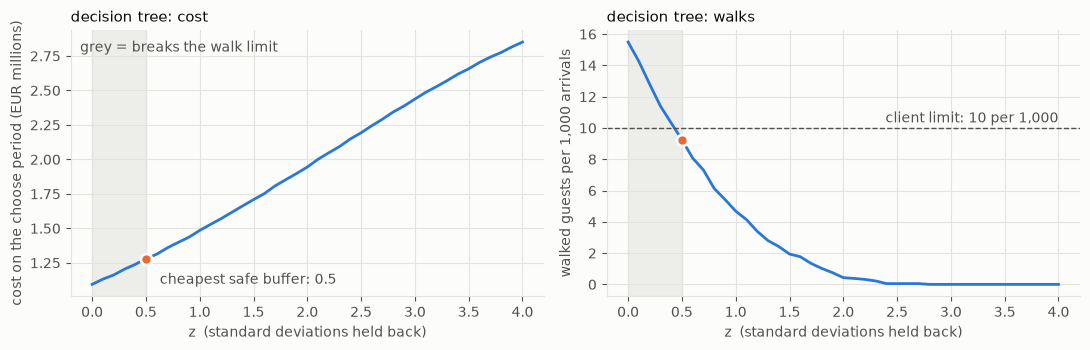

In [20]:
def nightly_error(nights):
    """Average gap, in rooms, between expected and real cancellations per night."""
    return (nights["expected"] - nights["cancelled"]).abs().mean()


nights_choose = contract.nightly_table(choose, chances_choose)      # one row per hotel and night
best_z, best = find_best_buffer(nights_choose)                       # the cheapest z inside the walk limit
rooms_held_back = avg_rooms_held_back(nights_choose, best_z)

print(f"Best buffer on the choose period: z = {best_z} std devs "
      f"= {rooms_held_back:.1f} rooms held back per night on average")
display(pd.Series({
    "cost (EUR)": best["cost_eur"],
    "empty rooms": best["empty_rooms"],
    "walked guests": best["walked_guests"],
    "walks per 1,000 arrivals": best["walks_per_1000"],
    "walk limit met (<= 10)": best["ceiling_met"],
    "nights scored": best["nights"],
    "nightly error (rooms)": round(nightly_error(nights_choose), 2),
}, name="decision tree on the choose period").to_frame())

sweep = sweep_buffers(nights_choose)
plot_buffer_sweep(sweep, best_z, "z  (standard deviations held back)", "decision tree")

**Reading the chart.** Cost rises with `z` (more empty rooms) while walks fall. The grey zone is every `z` that walks too many guests, so it is not allowed even though it is cheaper. The orange dot is the cheapest `z` just outside it.

### The client's flat rule (the yardstick)

The contract says every saving is a saving **against the client's flat rule**, never against selling nothing extra. The flat rule gives each booking its hotel's average cancellation rate from train, then holds back a fixed number of rooms (its margin, chosen on the choose period under the same walk limit).

In [21]:
# The client's flat rule is only a yardstick (it is not one of our models):
#   chance of cancelling = that hotel's cancellation rate in TRAIN, k = floor(rate x bookings) - margin.
# Every saving is measured against it, never against "sell nothing extra".
hotel_rate = train.groupby("hotel")["is_canceled"].mean()


def flat_rule_nights(df):
    chances = df["hotel"].map(hotel_rate).to_numpy()       # every booking gets its hotel's average rate
    return contract.nightly_table(df, chances)


flat_choose = flat_rule_nights(choose)
flat_margin, flat_best = find_best_buffer(flat_choose, kind="margin")
print(f"Client's flat rule: hotel rates from train {hotel_rate.round(3).to_dict()}")
print(f"Best safety margin on the choose period: {flat_margin} rooms  "
      f"(cost EUR {flat_best['cost_eur']:,.0f}, walks per 1,000 {flat_best['walks_per_1000']})")


comparison = pd.DataFrame([
    {"rule": "client's flat rule", "buffer": f"{flat_margin} rooms",
     "cost EUR": flat_best["cost_eur"], "empty rooms": flat_best["empty_rooms"],
     "walked guests": flat_best["walked_guests"], "walks per 1,000": flat_best["walks_per_1000"],
     "limit met": flat_best["ceiling_met"], "saving vs flat rule EUR": 0.0},
    {"rule": "decision tree + z-buffer", "buffer": f"z = {best_z} (~{rooms_held_back:.1f} rooms)",
     "cost EUR": best["cost_eur"], "empty rooms": best["empty_rooms"],
     "walked guests": best["walked_guests"], "walks per 1,000": best["walks_per_1000"],
     "limit met": best["ceiling_met"], "saving vs flat rule EUR": flat_best["cost_eur"] - best["cost_eur"]},
]).set_index("rule")
display(comparison)

Client's flat rule: hotel rates from train {'City Hotel': 0.417, 'Resort Hotel': 0.252}
Best safety margin on the choose period: 16 rooms  (cost EUR 2,416,541, walks per 1,000 9.25)


,buffer,cost EUR,empty rooms,walked guests,"walks per 1,000",limit met,saving vs flat rule EUR
rule,,,,,,,
client's flat rule,16 rooms,2416540.66,5529,172,9.25,True,0.00
decision tree + z-buffer,z = 0.5 (~1.7 rooms),1279279.00,2908,172,9.25,True,1137261.66


### Do bookings on the same night cancel independently?

Every one of these models (and the contract's `spread`) assumes **independent bookings**. That cannot be tested before the model exists, so we test it now. If bookings are independent, the real night-to-night gap `cancelled − expected` should have the same variance as the contract's `spread²`, a ratio of about 1.

In [22]:
gap = nights_choose["cancelled"] - nights_choose["expected"]
variance_ratio = gap.var() / (nights_choose["spread"] ** 2).mean()
print(f"real variance of (cancelled - expected) / variance the contract assumes = {variance_ratio:.1f}")
if variance_ratio <= 1.5:
    print("About 1: bookings behave as if independent, so the spread is a fair measure of the risk.")
else:
    print(f"Well above 1: bookings on the same night cancel more together than independence allows, so the "
          f"real swings are about {variance_ratio ** 0.5:.1f}x bigger than `spread` says.\n"
          "The independence assumption is only roughly true. This is not a reason to stop, but it is why "
          "the buffer z is FOUND by search on the choose period instead of being taken from a textbook "
          "value like 1.64.")

real variance of (cancelled - expected) / variance the contract assumes = 8.7
Well above 1: bookings on the same night cancel more together than independence allows, so the real swings are about 3.0x bigger than `spread` says.
The independence assumption is only roughly true. This is not a reason to stop, but it is why the buffer z is FOUND by search on the choose period instead of being taken from a textbook value like 1.64.


## 7. Proof: the final exam (run once, at the very end)

The contract allows **one** look at the proof period (1 January to 31 August 2017). We use the model exactly as trained above and the `z` and margin chosen on the choose period. **Nothing is changed after seeing the result.** If you do change something afterwards, the contract says to report both runs.

Set `RUN_PROOF = True` in the switches cell only when everything else is final.

In [23]:
if not RUN_PROOF:
    print("RUN_PROOF is False, so the proof period was NOT used. Set it to True for the final run.")
    proof_row = None
else:
    chances_proof = predict_chances(model, proof)
    proof_scores = get_scores(proof, chances_proof)
    nights_proof = contract.nightly_table(proof, chances_proof)
    model_proof = contract.night_cost(nights_proof, calculate_k(nights_proof, best_z))          # the z chosen earlier

    flat_nights_proof = flat_rule_nights(proof)
    flat_proof = contract.night_cost(flat_nights_proof, calculate_k(flat_nights_proof, flat_margin, "margin"))

    proof_row = pd.DataFrame([
        {"rule": "client's flat rule", "accuracy": None, "AUC": None, "cost EUR": flat_proof["cost_eur"],
         "empty rooms": flat_proof["empty_rooms"], "walked guests": flat_proof["walked_guests"],
         "walks per 1,000": flat_proof["walks_per_1000"], "limit met": flat_proof["ceiling_met"],
         "saving vs flat rule EUR": 0.0},
        {"rule": "decision tree + z-buffer", "accuracy": proof_scores["accuracy"], "AUC": proof_scores["auc"],
         "cost EUR": model_proof["cost_eur"], "empty rooms": model_proof["empty_rooms"],
         "walked guests": model_proof["walked_guests"], "walks per 1,000": model_proof["walks_per_1000"],
         "limit met": model_proof["ceiling_met"],
         "saving vs flat rule EUR": flat_proof["cost_eur"] - model_proof["cost_eur"]},
    ]).set_index("rule")
    display(proof_row.round(3))

RUN_PROOF is False, so the proof period was NOT used. Set it to True for the final run.


## 8. One-line summary

In [24]:
summary = pd.Series({
    "model": "decision tree",
    "assumptions": verdict,
    "accuracy (choose)": round(scores["accuracy"], 3),
    "always-'stays' accuracy": round(scores["always_stays"], 3),
    "AUC (choose)": round(scores["auc"], 3),
    "z chosen (std devs)": best_z,
    "cost EUR (choose)": best["cost_eur"],
    "walks per 1,000 (choose)": best["walks_per_1000"],
    "walk limit met": best["ceiling_met"],
    "saving vs flat rule EUR (choose)": round(flat_best["cost_eur"] - best["cost_eur"], 2),
    "proof run": "done" if RUN_PROOF else "not run",
}, name="result")
display(summary.to_frame())

,result
model,decision tree
assumptions,PASS
accuracy (choose),0.732
always-'stays' accuracy,0.631
AUC (choose),0.723
z chosen (std devs),0.5
cost EUR (choose),1279279.0
"walks per 1,000 (choose)",9.25
walk limit met,True
saving vs flat rule EUR (choose),1137261.66
